# Block-Encoding with FABLE

**Embedding an arbitrary matrix into a quantum circuit**

A quantum computation is a sequence of *unitary* operations, so a circuit can only ever implement
a unitary matrix. But many problems are phrased with matrices that are **not** unitary — a
diffusion operator, a sparse linear system, a state-transition matrix. **Block-encoding** is the
standard way to embed such a matrix inside a larger unitary: the matrix appears as a *block* of a
bigger unitary, so it can be applied (in a controlled, scaled way) by a quantum circuit.

This notebook:

1. explains what a block-encoding is;
2. shows how to **verify** that a circuit really block-encodes a given matrix;
3. uses the **FABLE** library (`pip install fable-circuits`) to build block-encoding circuits for
   a random matrix and for a **diffusion operator**, and checks them numerically;
4. shows how the circuit cost scales with the matrix size.

Requires `numpy`, `matplotlib`, `qiskit`, `qiskit-aer` and `fable-circuits`.

## Environment

```bash
pip install numpy matplotlib qiskit qiskit-aer fable-circuits
```

> Note: with Qiskit 1.x the Aer simulator is imported from `qiskit_aer` (not `from qiskit import
> Aer`). The FABLE call `fable(A, eps)` returns a Qiskit `QuantumCircuit` and the subnormalization
> factor `alpha`.

## 1. What is a block-encoding?

Let $A$ be an $N \times N$ matrix with $N = 2^n$, and let $U$ be a unitary on more qubits. $U$ is
an $(\alpha, \varepsilon, m)$-**block-encoding** of $A$ if

$$\left\| A - \alpha\,\big(\langle 0^m| \otimes I_n\big)\;U\;\big(|0^m\rangle \otimes I_n\big)
\right\| \le \varepsilon .$$

In words: put the $m$ **ancilla** qubits in $|0^m\rangle$, apply $U$, and project the ancilla back
onto $|0^m\rangle$. What you get is the matrix $A$ scaled by $\alpha$, up to an error
$\varepsilon$. Written as a block matrix,

$$U = \begin{bmatrix} A/\alpha & \cdot \\ \cdot & \cdot \end{bmatrix},$$

the top-left block of $U$ (the subspace where the ancilla are all $|0\rangle$) is $A/\alpha$. The
rest of $U$ is arbitrary, but it must be filled in so that $U$ is unitary.

The scalar $\alpha \ge \|A\|$ is the **subnormalization factor**: it pays for the fact that $A$
may have norm larger than $1$, and it is needed to keep $U$ unitary.

## 2. Why it matters

Block-encoding is a primitive of modern quantum algorithms. If you can block-encode an operator,
you can apply it inside a larger algorithm:

- **HHL / quantum linear solvers**: block-encode the matrix $A$ of the linear system $Ax=b$;
- **Quantum singular value transformation (QSVT)**: build polynomials of $A$ from its
  block-encoding, which is how many "quantum advantage" algorithms are assembled;
- **Hamiltonian / state evolution**: block-encode a generator and approximate its exponential.

It is also the natural way to bring a *classical* operator onto a quantum computer. For the
diffusion equation of this hackathon, block-encoding the discrete diffusion (Laplacian) operator is
the first step towards a quantum solver of the equation — and it is exactly what we do below.

## 3. FABLE

**FABLE** (Fast Approximate BLock-Encodings, Camps & Van Beeumen, 2022) synthesises a quantum
circuit that block-encodes a given matrix. It is designed for **dense, unstructured** matrices and
its gate count scales linearly with the number of matrix elements, which is optimal for the
unstructured case. It also includes a **compression** step that can drastically reduce the circuit
when the matrix has structure.

```bash
pip install fable-circuits
```

The API is minimal:

```python
from fable import fable

circ, alpha = fable(A, eps)
```

- `A` : the matrix to block-encode (square, size $2^n$);
- `eps` : optional compression threshold (coefficients below it are dropped);
- `circ` : a Qiskit circuit on $2n+1$ qubits that block-encodes `A`;
- `alpha` : the subnormalization factor returned by FABLE (the largest absolute entry of `A`).

Note that the block-encoding produced by FABLE carries an extra factor of $N = 2^n$: the leading
$N \times N$ block of the unitary is $A/(\alpha N)$. So

$$A \approx \alpha\,N\,\big(\langle 0^m|\otimes I_n\big)\,U\,\big(|0^m\rangle\otimes I_n\big).$$

We verify exactly this relation below.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from fable import fable
from qiskit_aer import Aer

simulator = Aer.get_backend("unitary_simulator")

def block_encoding(A, eps=1e-6):
    """FABLE block-encoding of A, returned with a check of the relation.

    Returns (circuit, alpha, unitary, relative_error).
    """
    N = A.shape[0]
    circ, alpha = fable(A, eps)
    U = simulator.run(circ).result().get_unitary(circ)
    # leading N x N block should be A / (alpha * N)
    block = U.data[:N, :N]
    err = np.linalg.norm(alpha * N * block - A) / np.linalg.norm(A)
    return circ, alpha, U, err

def circuit_stats(circ):
    ops = circ.count_ops()
    return circ.num_qubits, circ.depth(), sum(ops.values())

print("setup ok")

setup ok


## Example 1: a random matrix

Take a random $8\times 8$ matrix ($n=3$), block-encode it with FABLE, simulate the circuit and
compare the leading $8\times 8$ block to $A/(\alpha N)$. The relative error should be at machine
precision — the block-encoding is exact.

matrix: 8x8  (n=3 qubits)
circuit: 7 qubits, depth 130, 137 gates
subnormalization factor alpha = 2.3015
relative block-encoding error = 7.751e-16


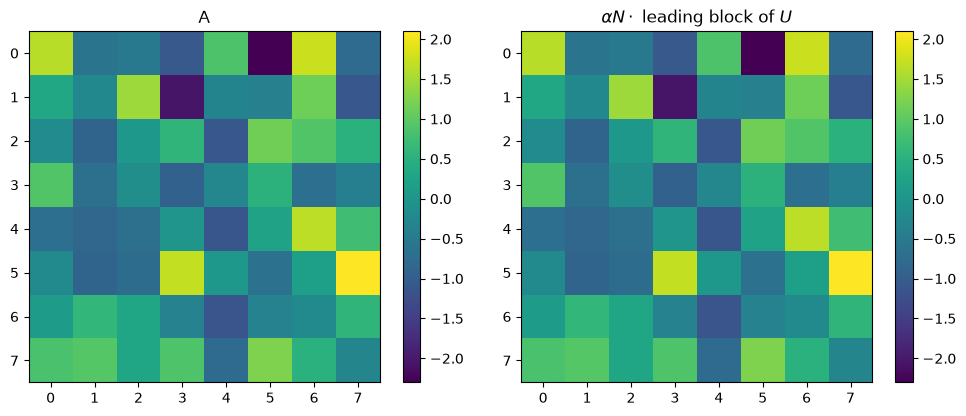

In [ ]:
np.random.seed(1)
n = 3
N = 2**n
A = np.random.randn(N, N)                 # a dense, unstructured matrix

circ, alpha, U, err = block_encoding(A)
nq, depth, gates = circuit_stats(circ)

print(f"matrix: {N}x{N}  (n={n} qubits)")
print(f"circuit: {nq} qubits, depth {depth}, {gates} gates")
print(f"subnormalization factor alpha = {alpha:.4f}")
print(f"relative block-encoding error = {err:.3e}")

random_gates = gates          # remember for the structured comparison below

# visual check: leading block vs A/(alpha*N)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(np.real(A), cmap='viridis'); plt.colorbar(); plt.title('A')
plt.subplot(1, 2, 2)
plt.imshow(np.real(alpha * N * U.data[:N, :N]), cmap='viridis'); plt.colorbar()
plt.title(r'$\alpha N \cdot$ leading block of $U$')
plt.tight_layout(); plt.show()

## Example 3: Collision matrice

Now we will encode the Collision matrix with C = (1-1/$\tau$)I + M/$\tau$, with : 
- I the identity matrix
- M the matrix of weight


In [16]:
from scipy.linalg import block_diag

tau = 0.8
omega = 1/tau
w = np.array([2/3, 1/6, 1/6])
C = (1 - omega)*np.eye(3) + omega*np.outer(w, np.ones(3))   # collision d'un nœud

N_noeuds = 100
K = block_diag(*[C]*N_noeuds)                  # collision : I_N ⊗ C (3N x 3N)

# streaming, ordre nœud par nœud (k = 3i + a)
P = np.roll(np.eye(N_noeuds), 1, axis=0)       # (P g)_i = g_{i-1} : décalage vers la droite
E0, Ep, Em = np.diag([1, 0, 0]), np.diag([0, 1, 0]), np.diag([0, 0, 1])
S = np.kron(np.eye(N_noeuds), E0) + np.kron(P, Ep) + np.kron(P.T, Em)

L = S @ K                                      # un pas complet

# vérifications

f = np.random.rand(3, N_noeuds)                # tableau (3, N)
v = f.T.ravel()                                # rangement nœud par nœud
fs = C @ f
f_classique = np.array([fs[0], np.roll(fs[1], 1), np.roll(fs[2], -1)])


# block-encoding FABLE du pas complet (complété à 32 x 32)
N = 2**int(np.ceil(np.log2(L.shape[0])))
n = int(np.log2(N))
A = np.zeros((N, N)); A[:L.shape[0], :L.shape[0]] = L

circ, alpha, U, err = block_encoding(A)
nq, depth, gates = circuit_stats(circ)
print(f"matrix: {N}x{N}  (n={n} qubits)")
print(f"circuit: {nq} qubits, depth {depth}, {gates} gates")
print(f"subnormalization factor alpha = {alpha:.4f}  ->  facteur effectif alpha*N = {alpha*N:.0f}")
print(f"relative block-encoding error = {err:.3e}")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(K, cmap='viridis'); ax[0].set_title('K = I_N ⊗ C (collision)')
ax[1].imshow(S, cmap='viridis'); ax[1].set_title('S (streaming, nœud par nœud)')
ax[2].imshow(np.real(alpha * N * U), cmap='viridis'); ax[2].set_title(r'$\alpha N \cdot$ bloc de $U$ = L')
plt.tight_layout(); plt.show()

Simulation failed and returned the following error message:
ERROR:  [Experiment 0] Insufficient memory to run circuit circuit-83 using the unitary simulator. Required memory: 4194304M, max memory: 16384M


QiskitError: 'Data for experiment "circuit-83" could not be found.'

## Example 2: a diffusion operator

Now block-encode the **discrete 1D Laplacian** — the operator of the diffusion equation
$\partial_t u = \nu\,\partial_{xx}u$ on a periodic grid. Its matrix is tridiagonal with
$-2$ on the diagonal and $1$ on the off-diagonals (wrapping around).

This is a *structured* matrix, so the FABLE compression step should produce a **much smaller
circuit** than for a random matrix of the same size — even though the block-encoding is still exact.

diffusion operator: 8x8
circuit: 7 qubits, depth 40, 47 gates
alpha = 2.0000  (largest absolute entry)
relative block-encoding error = 6.098e-16

(For comparison, the random 8x8 matrix used 137 gates.)


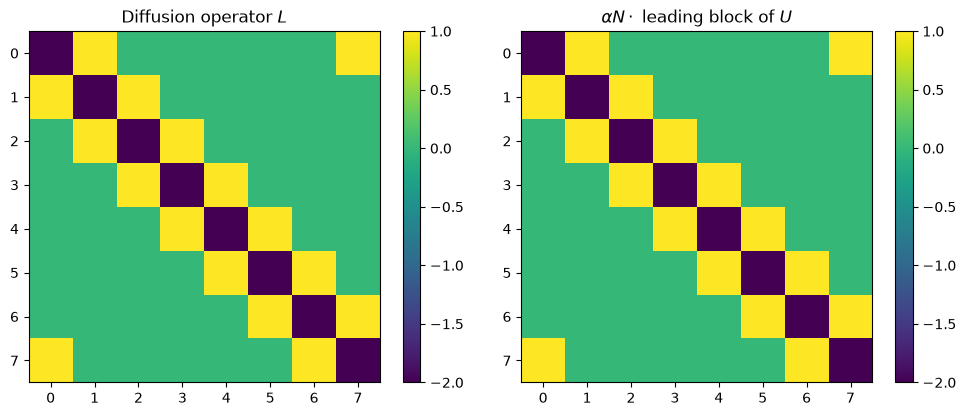

In [5]:
n = 3
N = 2**n

# 1D periodic Laplacian (diffusion operator)
L = np.zeros((N, N))
for i in range(N):
    L[i, i] = -2.0
    L[i, (i + 1) % N] = 1.0
    L[i, (i - 1) % N] = 1.0

circ, alpha, U, err = block_encoding(L)
nq, depth, gates = circuit_stats(circ)

print(f"diffusion operator: {N}x{N}")
print(f"circuit: {nq} qubits, depth {depth}, {gates} gates")
print(f"alpha = {alpha:.4f}  (largest absolute entry)")
print(f"relative block-encoding error = {err:.3e}")

# compare with the random matrix of the same size (from above)
print(f"\n(For comparison, the random {N}x{N} matrix used {random_gates} gates.)")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(L, cmap='viridis'); plt.colorbar(); plt.title('Diffusion operator $L$')
plt.subplot(1, 2, 2)
plt.imshow(np.real(alpha * N * U.data[:N, :N]), cmap='viridis'); plt.colorbar()
plt.title(r'$\alpha N \cdot$ leading block of $U$')
plt.tight_layout(); plt.show()

## How the cost scales

Block-encoding a **dense** matrix is expensive: FABLE's gate count grows like the number of matrix
elements, $\mathcal{O}(N^2) = \mathcal{O}(4^n)$. So the circuit grows exponentially in the number
of qubits — this is why block-encodings are only practical for small, sparse, or structured
operators, and why the compression step matters.

In [6]:
print(f"{'n':>2} {'N':>5} {'qubits':>7} {'depth':>8} {'gates':>8}")
for n in range(2, 6):
    N = 2**n
    A = np.random.randn(N, N)
    circ, alpha, U, err = block_encoding(A, eps=1e-3)
    nq, depth, gates = circuit_stats(circ)
    print(f"{n:>2} {N:>5} {nq:>7} {depth:>8} {gates:>8}")

print("\nThe gate count roughly quadruples each time n grows by 1 "
      "(~4^n = N^2), i.e. it scales with the number of matrix entries.")

 n     N  qubits    depth    gates
 2     4       5       34       38
 3     8       7      130      137
 4    16       9      513      523
 5    32      11     1993     2006

The gate count roughly quadruples each time n grows by 1 (~4^n = N^2), i.e. it scales with the number of matrix entries.


## References

- D. Camps, R. Van Beeumen, *FABLE: Fast Approximate Quantum Circuits for Block-Encodings*,
  IEEE QCE 2022, arXiv:2205.00081. Code: github.com/QuantumComputingLab/fable.
- A. Gilyén, Y. Su, G. H. Low, N. Wiebe, *Quantum singular value transformation and beyond*,
  STOC 2019, arXiv:1806.01838.
- A. W. Harrow, A. Hassidim, S. Lloyd, *Quantum algorithm for linear systems of equations*,
  Phys. Rev. Lett. 103 (2009) 150502.